# Science case: stellar metallicities with the Bench

At R ~ 1800 the Bench sample configuration is LAMOST-like (LAMOST LRS is R ~ 1800 over 370 to
900 nm), so LAMOST tells us what to expect. Survey pipelines at that resolution deliver [Fe/H] to
about 0.1 dex for FGK stars once the SNR per pixel exceeds 20 to 30 (LAMOST LASP: Wu et al.
2014, Luo et al. 2015; SEGUE SSPP: about 0.11 dex for high-SNR F and G stars, Allende Prieto et
al. 2008), with a floor near 0.1 dex. About 0.05 dex is reached only by data-driven methods
trained on high-resolution labels (Ho et al. 2017; Xiang et al. 2019), and those need SNR > 50.
The ETC works per resel (2.2 pixels here), so SNR 20 per pixel is about 30 per resel. The 412 to
686 nm window contains Ca I 422.7, the G band, the Fe and Mg b lines at 516 to 519 nm and Na D at
589 nm, which is where the metallicity sensitivity comes from.

Assumptions, all of them changeable in the first code cell:

* SNR per resel targets of 30 (about 0.1 dex, LAMOST-like) and 75 (what the 0.05 dex data-driven
  methods need).
* Metric window 500 to 560 nm (the Mg b region).
* Stars as blackbodies normalised in V: 5800 K (G dwarf), 4500 K (K dwarf), 3500 K (M dwarf).
  The M dwarf is included only for the photon budget. M-dwarf metallicities at R ~ 1800 do not
  come from Mg b or Na D, and LAMOST M-dwarf [Fe/H] values are poor, so read that row as a
  throughput number and nothing more.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
stars = {"G dwarf 5800 K": 5800, "K dwarf 4500 K": 4500, "M dwarf 3500 K": 3500}
mags = np.linspace(9, 20, 45)
window = (500, 560)

## Exposure time to reach the SNR thresholds

Left panel SNR 30, right panel SNR 75. The horizontal lines mark 15 minutes and one hour. The
three curves lie almost on top of each other. That is expected: the metric window sits inside the
V band, where the magnitude pins the flux, so spectral type only enters through the slope of the
SED across the 60 nm window. Spectral type would matter if the window were far from the band in
which the magnitude is known (try I-band normalisation).

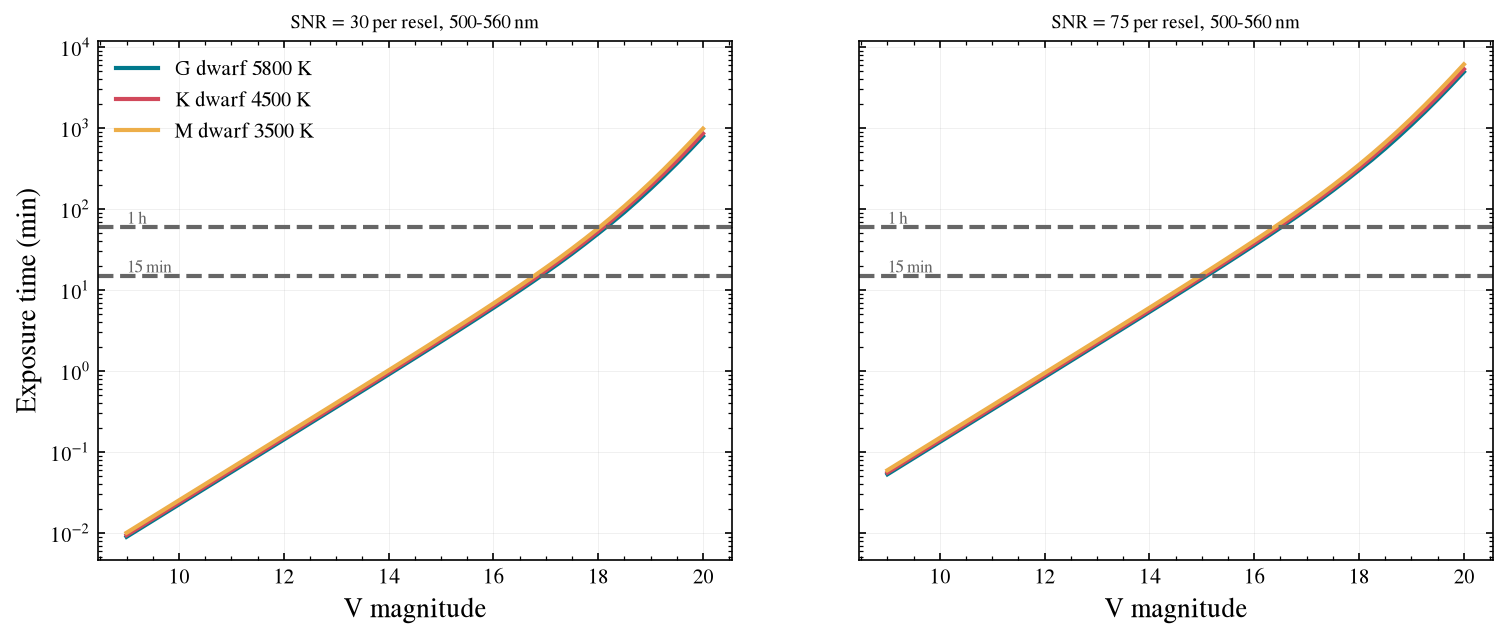

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, snr_t in zip(axes, (30, 75)):
    for label, teff in stars.items():
        t = bench.exptime_vs_mag(Source.blackbody(teff, 0, "V"), mags, snr=snr_t, wavelength=window)
        ax.plot(mags, t/60, label=label)
    ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_title(f"SNR = {snr_t} per resel, 500-560 nm", fontsize=9)
    for h, txt in ((15, "15 min"), (60, "1 h")):
        ax.axhline(h, color='0.4', ls='--'); ax.text(mags[0], h*1.1, txt, fontsize=8, color='0.4')
axes[0].set_ylabel("Exposure time (min)"); axes[0].legend();

## Survey depth: limiting magnitude per exposure length

In [4]:
for exp in (300, 900, 3600):
    row = []
    for label, teff in stars.items():
        m30 = bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), exp, 30, wavelength=window)
        m75 = bench.limiting_magnitude(Source.blackbody(teff, 0, "V"), exp, 75, wavelength=window)
        row.append(f"{label.split()[0]}: V<{m30:.1f} (SNR30) / V<{m75:.1f} (SNR75)")
    print(f"{exp:5d} s  " + " | ".join(row))

  300 s  G: V<15.8 (SNR30) / V<13.9 (SNR75) | K: V<15.8 (SNR30) / V<13.9 (SNR75) | M: V<15.7 (SNR30) / V<13.8 (SNR75)
  900 s  G: V<16.9 (SNR30) / V<15.1 (SNR75) | K: V<16.9 (SNR30) / V<15.0 (SNR75) | M: V<16.8 (SNR30) / V<15.0 (SNR75)
 3600 s  G: V<18.2 (SNR30) / V<16.5 (SNR75) | K: V<18.1 (SNR30) / V<16.5 (SNR75) | M: V<18.0 (SNR30) / V<16.4 (SNR75)


## Where the information comes from: SNR across the band

The metallicity indicators are spread over the window, and the SNR per resel is far from flat
across it because the throughput and the stellar SED both change strongly between 412 and 686 nm.
The dotted lines mark the main features. For the cool stars the blue end, where Ca I and the G
band sit, is where the SNR is lowest.

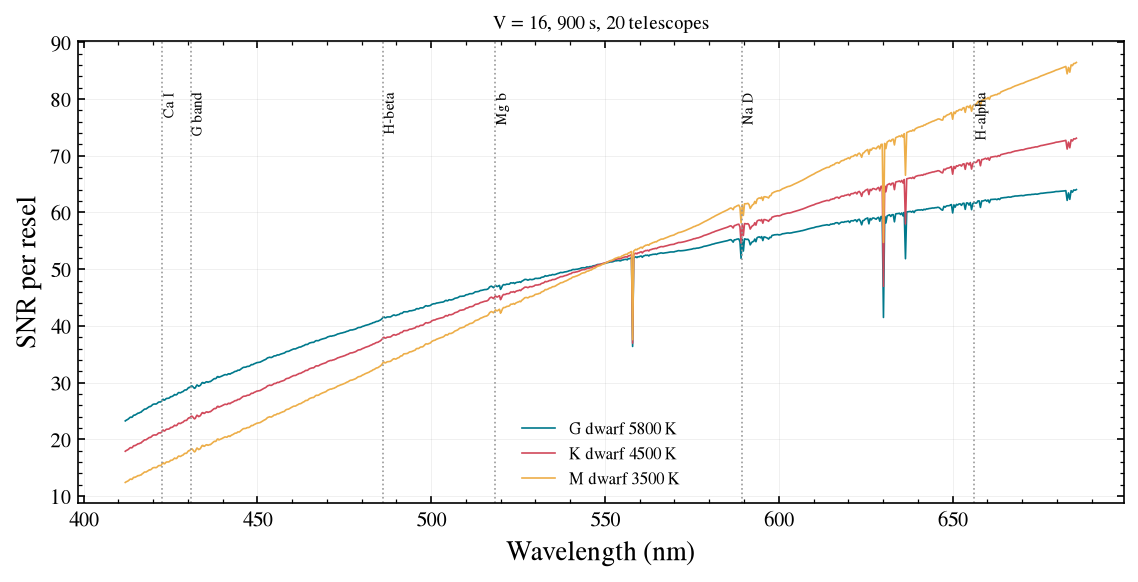

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, teff in stars.items():
    r = bench.snr(Source.blackbody(teff, 16, "V"), exptime=900)
    ax.plot(r.wavelength, r.snr, lw=0.8, label=label)
ymax = ax.get_ylim()[1]
for w, name in ((422.7, "Ca I"), (430.8, "G band"), (486.1, "H-beta"), (518.4, "Mg b"), (589.3, "Na D"), (656.3, "H-alpha")):
    ax.axvline(w, color='0.6', ls=':', lw=0.8); ax.text(w, ymax*0.9, name, fontsize=7, rotation=90, va='top')
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("SNR per resel"); ax.set_title("V = 16, 900 s, 20 telescopes", fontsize=9)
ax.legend(fontsize=8);

## Survey throughput

Stars per 8 hour night as a function of magnitude for the SNR 30 target, with 2 minutes of
overhead per target. All fibers point at one star, so there is no multiplexing: this is a
one-target-at-a-time instrument.

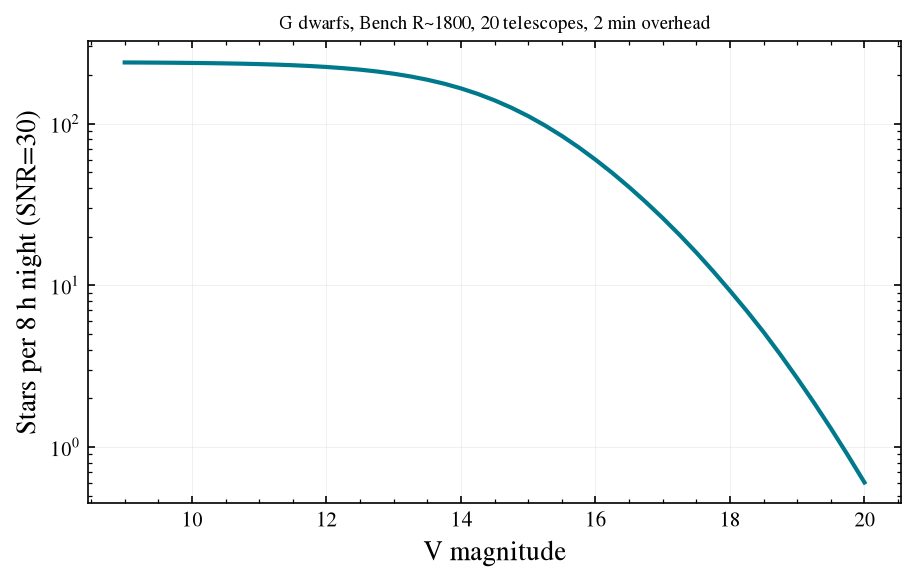

In [6]:
overhead = 120.0
t = bench.exptime_vs_mag(Source.blackbody(5800, 0, "V"), mags, snr=30, wavelength=window)
n_per_night = 8*3600 / (t + overhead)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mags, n_per_night)
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Stars per 8 h night (SNR=30)")
ax.set_title("G dwarfs, Bench R~1800, 20 telescopes, 2 min overhead", fontsize=9);

## Array size and survey depth at SNR 30 in 15 minutes

In [7]:
for n in (5, 10, 20, 40, 80):
    e = LFASTETC("bench_r1800", n_telescopes=n)
    print(f"N={n:3d}: V_lim(SNR=30, 15 min) = {e.limiting_magnitude(Source.blackbody(5800,0,'V'), 900, 30, wavelength=window):.2f}")

N=  5: V_lim(SNR=30, 15 min) = 15.51
N= 10: V_lim(SNR=30, 15 min) = 16.23
N= 20: V_lim(SNR=30, 15 min) = 16.91
N= 40: V_lim(SNR=30, 15 min) = 17.53
N= 80: V_lim(SNR=30, 15 min) = 18.09


## Things to try

* Move the metric window to the G band (425 to 435 nm) and compare the depth. This is the window
  that matters for carbon-enhanced metal-poor stars.
* Switch to the `bench_1200_28p7_o2` preset (R ~ 3700 around 400 nm). Does the higher resolution
  pay for itself in exposure time at fixed SNR per resel?